# 14_lstm_sequence.ipynb — LSTM บนประวัติการ admit (ขั้นที่ 4 จาก 4)

## คำถาม
การมองข้อมูลเป็น **ลำดับของ encounter** ของผู้ป่วยแต่ละคน ช่วยทำนายได้ดีกว่าการดูแค่ encounter ปัจจุบันไหม?

## ข้อจำกัดของข้อมูลที่ต้องรู้ก่อน
- ~76% ของผู้ป่วยมีแค่ 1 encounter → ส่วนใหญ่ไม่มีลำดับให้ LSTM เรียนรู้
- ไม่มีวันที่ เรียงลำดับด้วย `encounter_id` (สมมติฐาน: เลขเรียงตามเวลา — ต้องเขียนในเปเปอร์)

## ข้อมูลใหม่ที่ได้จากการมองเป็นลำดับ: ผลลัพธ์ของ encounter ก่อนหน้า
ณ วันที่ผู้ป่วยมา admit ครั้งนี้ เรารู้แล้วว่าครั้งก่อนเขากลับมาภายใน 30 วันหรือไม่ (เพราะครั้งนี้ก็คือการกลับมานั่นเอง) จึงใช้ได้โดย**ไม่ leak** label ของครั้งปัจจุบัน

## การออกแบบการทดลองแบบ ablation (เปลี่ยนทีละอย่าง)

| โมเดล | Feature ครั้งปัจจุบัน | สรุปประวัติ (label ครั้งก่อน + จำนวนครั้ง) | รายละเอียดทุก encounter ก่อนหน้า |
|---|---|---|---|
| **A. XGBoost tuned** (baseline จาก 13b) | ✓ | | |
| **B. XGBoost tuned + history** | ✓ | ✓ | |
| **C. LSTM, K=1** (ไม่มีลำดับ) | ✓ | ✓ | |
| **D. LSTM, K=5** | ✓ | ✓ | ✓ (สูงสุด 4 ครั้งก่อนหน้า) |

- **B − A** = ประโยชน์ของข้อมูลประวัติ
- **D − C** = ประโยชน์ของ *sequence modeling* จริงๆ (สถาปัตยกรรมเดียวกัน ต่างกันแค่ความยาวลำดับ)
- **D − B** = LSTM เทียบกับโมเดลที่ดีที่สุดแบบต้นไม้ ที่ได้ข้อมูลประวัติเท่ากัน

## การตั้งค่าให้ตรงกับ notebook 15 (แก้ไขรอบนี้)
เดิม notebook นี้ใช้ 3 seed และ early stopping บน validation ทั้งชุด ส่วน notebook 15 ใช้ 5 seed และ early stopping บน `val_es` ทำให้ผลของ B และ D สองที่ไม่ตรงกัน รอบนี้แก้ให้ใช้การตั้งค่าเดียวกันทุกอย่าง:
- **5 seed** (42–46) สำหรับ LSTM ทั้ง C และ D
- แบ่ง validation เป็น `val_es` / `val_sel` ตามผู้ป่วยแบบเดียวกับ notebook 15 → **early stopping บน `val_es`** ทั้ง XGBoost และ LSTM
- ใช้ `build_history_features`, `build_nn_inputs`, `build_seq_index` จาก `readmission_features.py` ตัวเดียวกับ notebook 15
- Bootstrap บน test 500 รอบ เท่ากับ notebook 15

ผล A, B, D จึงต้องตรงกับ notebook 15 (มีเซลล์ตรวจท้ายหัวข้อ 5) ต้องรันบนเครื่องเดียวกับ notebook 15 เพราะ PyTorch บน CPU ต่างเครื่องอาจให้ผลต่างกันที่ทศนิยมหลักท้าย

ต้องการ: torch, xgboost, `readmission_features.py` (เวอร์ชันเดียวกับ notebook 15), `split_assignment.csv`

## 0. Config + Imports

In [1]:
LABEL_MODE = "30d"
RANDOM_STATE = 42
RAW_PATH = "../data/diabetic_data.csv"
SPLIT_PATH = "../outputs/split_assignment.csv"
OUT_DIR = f"../outputs/14_lstm_{LABEL_MODE}"
NB15_METRICS = f"../outputs/15_final_{LABEL_MODE}/test_metrics.csv"   # ใช้ตรวจว่าผลตรงกับ notebook 15

# ตั้งค่าเดียวกับ notebook 15 ทุกตัว
K_SEQ, N_SEEDS = 5, 5   # ความยาวลำดับสูงสุด (ปัจจุบัน + 4 ครั้งก่อน), จำนวน seed ที่เฉลี่ย
HIDDEN, DROPOUT, BATCH, LR, MAX_EPOCHS, PATIENCE = 64, 0.3, 512, 1e-3, 40, 5
N_BOOT_TEST = 500

In [2]:
import os, copy, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score

from readmission_features import (load_prepared, attach_split, build_history_features,
                                  build_nn_inputs, build_seq_index)

torch.set_num_threads(max(1, os.cpu_count() - 1))
os.makedirs(OUT_DIR, exist_ok=True)

## 1. โหลดข้อมูล + แบ่ง validation เป็น val_es / val_sel + history features

แบ่ง validation ตามผู้ป่วยด้วยโค้ดและ `random_state` เดียวกับ notebook 15 → `val_es` และ `val_sel` เป็นผู้ป่วยชุดเดียวกันทั้งสอง notebook
- `val_es` ใช้ early stopping
- `val_sel` ใช้รายงานผลบน validation (notebook นี้ไม่ได้เลือกโมเดล)

In [3]:
X, y, groups, meta, R = load_prepared(RAW_PATH, LABEL_MODE)
split = attach_split(meta, SPLIT_PATH).astype(object)

val_idx = np.where(split == "val")[0]
gss = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=RANDOM_STATE)
es_rel, sel_rel = next(gss.split(val_idx, groups=groups[val_idx]))
split[val_idx[es_rel]], split[val_idx[sel_rel]] = "val_es", "val_sel"

rows = {s: np.where(split == s)[0] for s in ["train", "val_es", "val_sel", "test"]}
y_np = y.values.astype(np.float32)
for s, r in rows.items():
    print(f"{s:8s} n={len(r):6,}  patients={len(np.unique(groups[r])):6,}  base rate={y_np[r].mean():.4f}")
assert len(set(groups[rows["val_es"]]) & set(groups[rows["val_sel"]])) == 0

Hist = build_history_features(meta)          # history features 5 ตัว (ฟังก์ชันเดียวกับ notebook 15)
visit_number = R["visit_number"].values
print(f"\nสัดส่วน encounter ที่มีประวัติในข้อมูล (visit ≥ 2): train {(visit_number[rows['train']] >= 2).mean():.3f}, "
      f"test {(visit_number[rows['test']] >= 2).mean():.3f}")

raw = meta["readmitted_raw"].values
pid = meta["patient_nbr"].values
same_prev = np.r_[False, pid[1:] == pid[:-1]]
prev_raw = np.where(same_prev, np.concatenate([["none"], raw[:-1]]), "none")
print("\nอัตรา readmit ตามผลของครั้งก่อน (train):")
print(pd.DataFrame({"prev": prev_raw[rows["train"]], "y": y_np[rows["train"]]})
      .groupby("prev")["y"].agg(["mean", "size"]).round(3))

train    n=63,605  patients=44,791  base rate=0.1142
val_es   n= 7,954  patients= 5,599  base rate=0.1118
val_sel  n= 8,008  patients= 5,599  base rate=0.1144
test     n=19,773  patients=13,998  base rate=0.1135

สัดส่วน encounter ที่มีประวัติในข้อมูล (visit ≥ 2): train 0.296, test 0.292

อัตรา readmit ตามผลของครั้งก่อน (train):
       mean   size
prev              
<30   0.220   5072
>30   0.149  13478
NO    0.466    264
none  0.090  44791


## 2. XGBoost baselines (A และ B)
Hyperparameter เดียวกับ notebook 13b และ 15, early stopping บน `val_es` (เหมือน notebook 15)

In [4]:
XGB_PARAMS = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist",
              "learning_rate": 0.03, "max_depth": 4, "subsample": 0.9, "min_child_weight": 5,
              "seed": RANDOM_STATE}

def fit_xgb(Xall):
    def dm(r, label=True):
        return xgb.DMatrix(Xall.iloc[r], label=y_np[r] if label else None)
    bst = xgb.train(XGB_PARAMS, dm(rows["train"]), num_boost_round=3000,
                    evals=[(dm(rows["val_es"]), "val_es")], early_stopping_rounds=100, verbose_eval=False)
    it = (0, bst.best_iteration + 1)
    return {s: bst.predict(dm(rows[s], False), iteration_range=it) for s in ["val_sel", "test"]}, bst.best_iteration + 1

preds = {}
preds["A. XGBoost tuned"], nA = fit_xgb(X)
preds["B. XGBoost tuned + history"], nB = fit_xgb(pd.concat([X, Hist], axis=1))
for k, n_trees in [("A. XGBoost tuned", nA), ("B. XGBoost tuned + history", nB)]:
    print(f"{k:30s} {n_trees:5d} trees | val_sel ROC-AUC = {roc_auc_score(y_np[rows['val_sel']], preds[k]['val_sel']):.4f}")

A. XGBoost tuned                 883 trees | val_sel ROC-AUC = 0.6695
B. XGBoost tuned + history       873 trees | val_sel ROC-AUC = 0.6758


## 3. เตรียม input สำหรับ neural network

ใช้ `build_nn_inputs` และ `build_seq_index` ตัวเดียวกับ notebook 15:
- Categorical (รวมรหัส ID และยาเบาหวาน) → **one-hot**
- Numeric → **standardize** ด้วย mean/SD ของ train เท่านั้น
- ต่อท้ายด้วย history features

ลำดับของแต่ละ encounter = encounter ปัจจุบัน + ครั้งก่อนหน้าสูงสุด K−1 ครั้ง (right-padded)
ในแต่ละ step มี "ผลของครั้งก่อนหน้า step นั้น" อยู่ใน input — ไม่มี label ของ step ปัจจุบันเด็ดขาด

In [5]:
F, nn_artifacts = build_nn_inputs(R, Hist, rows["train"])
D_IN = F.shape[1]
assert np.isfinite(F).all()
idx_k = {K: build_seq_index(visit_number, pid, K) for K in (1, K_SEQ)}
print(f"Input ต่อ encounter: {D_IN} มิติ")
L5 = idx_k[K_SEQ][1]
print("การกระจายของความยาวลำดับ (K=%d):" % K_SEQ, dict(zip(*np.unique(L5, return_counts=True))))

Input ต่อ encounter: 201 มิติ
การกระจายของความยาวลำดับ (K=5): {np.int64(1): np.int64(69987), np.int64(2): np.int64(16341), np.int64(3): np.int64(6123), np.int64(4): np.int64(2890), np.int64(5): np.int64(3999)}


## 4. LSTM

```
encounter features → Linear(64) + ReLU + Dropout → LSTM(64) → hidden สุดท้าย → Linear(64) + ReLU + Dropout → Linear(1)
```
ใช้ `pack_padded_sequence` ให้ LSTM ไม่ประมวลผลส่วนที่ pad
K=1 คือสถาปัตยกรรมเดียวกันแต่เห็นแค่ encounter ปัจจุบัน → ทำหน้าที่เป็น MLP ที่เป็น control ที่ยุติธรรมที่สุด

การฝึกเหมือน notebook 15 ทุกอย่าง: seed 42–46, early stopping บน ROC-AUC ของ `val_es`

In [6]:
F_pad = torch.from_numpy(np.vstack([F, np.zeros((1, D_IN), np.float32)]))
y_t = torch.from_numpy(y_np)

class SeqNet(nn.Module):
    def __init__(self, d_in, h=HIDDEN, drop=DROPOUT):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(drop))
        self.lstm = nn.LSTM(h, h, batch_first=True)
        self.head = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))
    def forward(self, x, lengths):
        packed = pack_padded_sequence(self.inp(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        return self.head(h_n[-1]).squeeze(-1)

def batch(K, r):
    idx, L = idx_k[K]
    return F_pad[torch.from_numpy(idx[r])], torch.from_numpy(L[r])

@torch.no_grad()
def predict_nn(model, K, r):
    model.eval()
    return torch.cat([torch.sigmoid(model(*batch(K, r[b:b + 4096]))) for b in range(0, len(r), 4096)]).numpy()

def train_nn(K, seed):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = SeqNet(D_IN)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    lossf = nn.BCEWithLogitsLoss()
    best, best_state, bad, hist = -1.0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = rng.permutation(rows["train"])
        for b in range(0, len(perm), BATCH):
            r = perm[b:b + BATCH]
            opt.zero_grad()
            loss = lossf(model(*batch(K, r)), y_t[torch.from_numpy(r)])
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc = roc_auc_score(y_np[rows["val_es"]], predict_nn(model, K, rows["val_es"]))
        hist.append(auc)
        if auc > best + 1e-4:
            best, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, hist

C. LSTM K=1 (no sequence) seed 0: epochs=21, val_es ROC-AUC=0.6877, test ROC-AUC=0.6887  (22s)
C. LSTM K=1 (no sequence) seed 1: epochs=22, val_es ROC-AUC=0.6864, test ROC-AUC=0.6867  (22s)
C. LSTM K=1 (no sequence) seed 2: epochs=26, val_es ROC-AUC=0.6874, test ROC-AUC=0.6870  (27s)
C. LSTM K=1 (no sequence) seed 3: epochs=17, val_es ROC-AUC=0.6846, test ROC-AUC=0.6858  (18s)
C. LSTM K=1 (no sequence) seed 4: epochs=22, val_es ROC-AUC=0.6873, test ROC-AUC=0.6859  (25s)
D. LSTM K=5 seed 0: epochs=27, val_es ROC-AUC=0.6884, test ROC-AUC=0.6868  (57s)
D. LSTM K=5 seed 1: epochs=26, val_es ROC-AUC=0.6881, test ROC-AUC=0.6874  (56s)
D. LSTM K=5 seed 2: epochs=25, val_es ROC-AUC=0.6919, test ROC-AUC=0.6877  (56s)
D. LSTM K=5 seed 3: epochs=26, val_es ROC-AUC=0.6903, test ROC-AUC=0.6867  (58s)
D. LSTM K=5 seed 4: epochs=25, val_es ROC-AUC=0.6890, test ROC-AUC=0.6859  (54s)


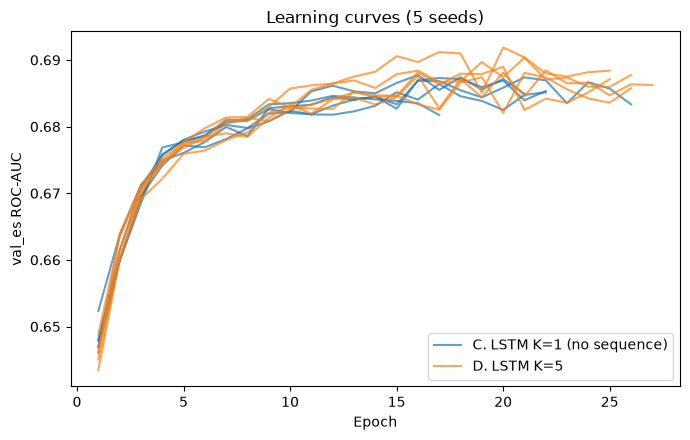

In [7]:
nn_runs = {}
for K, name in [(1, "C. LSTM K=1 (no sequence)"), (K_SEQ, f"D. LSTM K={K_SEQ}")]:
    pv, pt, per_seed, curves = [], [], [], []
    for s in range(N_SEEDS):
        t0 = time.time()
        model, best_auc, hist = train_nn(K, RANDOM_STATE + s)
        pv.append(predict_nn(model, K, rows["val_sel"]))
        pt.append(predict_nn(model, K, rows["test"]))
        test_auc = roc_auc_score(y_np[rows["test"]], pt[-1])
        per_seed.append({"seed": s, "epochs": len(hist), "val_es_auc": best_auc, "test_auc": test_auc})
        curves.append(hist)
        print(f"{name} seed {s}: epochs={len(hist):2d}, val_es ROC-AUC={best_auc:.4f}, "
              f"test ROC-AUC={test_auc:.4f}  ({time.time() - t0:.0f}s)")
    preds[name] = {"val_sel": np.mean(pv, axis=0), "test": np.mean(pt, axis=0)}   # seed ensemble
    nn_runs[name] = {"per_seed": pd.DataFrame(per_seed), "curves": curves}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, r in nn_runs.items():
    for i, c in enumerate(r["curves"]):
        ax.plot(range(1, len(c) + 1), c, color="C0" if "K=1" in name else "C1", alpha=0.7,
                label=name if i == 0 else None)
ax.set_xlabel("Epoch"); ax.set_ylabel("val_es ROC-AUC"); ax.legend(); ax.set_title(f"Learning curves ({N_SEEDS} seeds)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=150); plt.show()

## 5. เปรียบเทียบบน Test + Paired Bootstrap ตามผู้ป่วย

แยกผลเป็น 2 กลุ่มด้วย:
- **Encounter แรกในข้อมูล** (visit 1) — ไม่มีประวัติ LSTM ไม่ควรได้เปรียบ
- **มีประวัติ** (visit ≥ 2) — กลุ่มเดียวที่ sequence modeling มีโอกาสช่วย

In [8]:
te = rows["test"]
y_te = y_np[te]
g_te = groups[te]
first_visit = visit_number[te] == 1

def m(p, ii=slice(None)):
    return roc_auc_score(y_te[ii], p[ii]), average_precision_score(y_te[ii], p[ii])

res = []
for k, p in preds.items():
    pt = p["test"]
    a, ap = m(pt)
    a1, _ = m(pt, first_visit)
    a2, _ = m(pt, ~first_visit)
    res.append({"model": k, "ROC_AUC": a, "PR_AUC": ap,
                "ROC_AUC_first_visit": a1, "ROC_AUC_has_history": a2})
point = pd.DataFrame(res).set_index("model").round(4)
print(f"Test: n={len(te):,} | first visit={first_visit.sum():,} | has history={(~first_visit).sum():,} | "
      f"base rate={y_te.mean():.4f}\n")
print(point.to_string())

Test: n=19,773 | first visit=13,998 | has history=5,775 | base rate=0.1135

                            ROC_AUC  PR_AUC  ROC_AUC_first_visit  ROC_AUC_has_history
model                                                                                
A. XGBoost tuned             0.6795  0.2339               0.6504               0.6318
B. XGBoost tuned + history   0.6845  0.2452               0.6514               0.6546
C. LSTM K=1 (no sequence)    0.6899  0.2551               0.6604               0.6596
D. LSTM K=5                  0.6911  0.2540               0.6602               0.6642


### ตรวจว่าผลตรงกับ notebook 15
A, B และ D ฝึกด้วยข้อมูล การแบ่ง และ seed เดียวกับ notebook 15 จึงต้องได้ค่าเท่ากัน ถ้าไม่ตรง ให้ตรวจว่าใช้ `readmission_features.py` ตัวเดียวกัน และรันบนเครื่องเดียวกับ notebook 15

In [9]:
pairs = [("A. XGBoost tuned", "A. XGBoost tuned"),
         ("B. XGBoost tuned + history", "B. XGBoost + history"),
         (f"D. LSTM K={K_SEQ}", "D. LSTM K=5")]
if os.path.exists(NB15_METRICS):
    nb15 = pd.read_csv(NB15_METRICS, index_col=0)
    chk = pd.DataFrame([{"model": a,
                         "ROC_AUC nb14": point.loc[a, "ROC_AUC"], "ROC_AUC nb15": nb15.loc[b, "ROC_AUC"],
                         "PR_AUC nb14": point.loc[a, "PR_AUC"], "PR_AUC nb15": nb15.loc[b, "PR_AUC"]}
                        for a, b in pairs])
    chk["ตรงกัน"] = ((chk["ROC_AUC nb14"] - chk["ROC_AUC nb15"]).abs() < 5e-5) & \
                    ((chk["PR_AUC nb14"] - chk["PR_AUC nb15"]).abs() < 5e-5)
    print(chk.to_string(index=False))
    print("\n✓ ผลตรงกับ notebook 15 ทุกโมเดล" if chk["ตรงกัน"].all()
          else "\n⚠️ ยังไม่ตรง — ตรวจ readmission_features.py และเครื่องที่รัน")
else:
    print(f"ไม่พบ {NB15_METRICS} — รัน notebook 15 ก่อนเพื่อตรวจเทียบ")

                     model  ROC_AUC nb14  ROC_AUC nb15  PR_AUC nb14  PR_AUC nb15  ตรงกัน
          A. XGBoost tuned        0.6795        0.6795       0.2339       0.2339    True
B. XGBoost tuned + history        0.6845        0.6845       0.2452       0.2452    True
               D. LSTM K=5        0.6911        0.6911       0.2540       0.2540    True

✓ ผลตรงกับ notebook 15 ทุกโมเดล


In [10]:
comparisons = [("B. XGBoost tuned + history", "A. XGBoost tuned", "ประโยชน์ของข้อมูลประวัติ"),
               (f"D. LSTM K={K_SEQ}", "C. LSTM K=1 (no sequence)", "ประโยชน์ของ sequence modeling"),
               (f"D. LSTM K={K_SEQ}", "B. XGBoost tuned + history", "LSTM vs ต้นไม้ (ข้อมูลเท่ากัน)"),
               (f"D. LSTM K={K_SEQ}", "A. XGBoost tuned", "LSTM vs baseline")]

rng = np.random.default_rng(RANDOM_STATE)
uniq = np.unique(g_te)
by_pt = pd.Series(np.arange(len(g_te))).groupby(g_te).apply(np.array)
boot = {c[2]: {"all": [], "hist": []} for c in comparisons}
for b in range(N_BOOT_TEST):
    ii = np.concatenate(by_pt.loc[rng.choice(uniq, len(uniq), replace=True)].values)
    jj = ii[~first_visit[ii]]
    for new, old, label in comparisons:
        pn, po = preds[new]["test"], preds[old]["test"]
        boot[label]["all"].append(roc_auc_score(y_te[ii], pn[ii]) - roc_auc_score(y_te[ii], po[ii]))
        boot[label]["hist"].append(roc_auc_score(y_te[jj], pn[jj]) - roc_auc_score(y_te[jj], po[jj]))

def fmt(pointd, arr):
    lo, hi = np.percentile(arr, [2.5, 97.5])
    return f"{pointd:+.4f} ({lo:+.4f}, {hi:+.4f})" + (" *" if lo > 0 or hi < 0 else "")

rows_out = []
for new, old, label in comparisons:
    rows_out.append({
        "comparison": label, "new − old": f"{new[:2]} − {old[:2]}",
        "Δ ROC-AUC ทั้งหมด": fmt(point.loc[new, "ROC_AUC"] - point.loc[old, "ROC_AUC"], boot[label]["all"]),
        "Δ ROC-AUC กลุ่มมีประวัติ": fmt(point.loc[new, "ROC_AUC_has_history"] - point.loc[old, "ROC_AUC_has_history"],
                                      boot[label]["hist"]),
    })
delta = pd.DataFrame(rows_out)
print(f"ผลต่าง ROC-AUC + 95% CI จาก paired cluster bootstrap {N_BOOT_TEST} รอบ (* = มีนัยสำคัญ)\n")
print(delta.to_string(index=False))

ผลต่าง ROC-AUC + 95% CI จาก paired cluster bootstrap 500 รอบ (* = มีนัยสำคัญ)

                    comparison new − old            Δ ROC-AUC ทั้งหมด     Δ ROC-AUC กลุ่มมีประวัติ
      ประโยชน์ของข้อมูลประวัติ   B. − A. +0.0050 (+0.0024, +0.0077) * +0.0228 (+0.0129, +0.0340) *
 ประโยชน์ของ sequence modeling   D. − C.   +0.0012 (-0.0017, +0.0041)   +0.0046 (-0.0037, +0.0127)
LSTM vs ต้นไม้ (ข้อมูลเท่ากัน)   D. − B. +0.0066 (+0.0013, +0.0115) *   +0.0096 (-0.0020, +0.0207)
              LSTM vs baseline   D. − A. +0.0116 (+0.0058, +0.0171) * +0.0324 (+0.0172, +0.0483) *


## 6. บันทึกผล + แนวทางเขียนเปเปอร์

**วิธีอ่านผล**
- ถ้า **D − C** คร่อม 0 → รายละเอียดของ encounter ก่อนหน้าไม่ได้เพิ่มข้อมูลเกินกว่าที่สรุปไว้ใน feature ประวัติ
- ถ้า **B − A** เป็นบวกมีนัยสำคัญ → ข้อมูลประวัติ (โดยเฉพาะผลของครั้งก่อน) เป็น feature ที่ควรเพิ่มในโมเดลหลักของ notebook 15
- ดูคอลัมน์ "กลุ่มมีประวัติ" ประกอบเสมอ เพราะผลรวมถูกเจือจางด้วยผู้ป่วยที่ไม่มีประวัติ

**สิ่งที่ต้องอัปเดตในเปเปอร์หลังรัน**: ตารางที่ 4, ค่า Δ และ CI ในหัวข้อ 4.5, ลบประโยคเรื่อง 3 seed / 5 seed ในหัวข้อ 3.8 และ 4.6

**ข้อจำกัดที่ต้องเขียน**: การเรียงลำดับด้วย `encounter_id` เป็นสมมติฐาน, ไม่มีช่วงเวลาระหว่าง encounter, ประวัติมีเฉพาะที่อยู่ใน 130 โรงพยาบาลของ dataset

In [11]:
point.to_csv(f"{OUT_DIR}/test_metrics.csv")
delta.to_csv(f"{OUT_DIR}/test_deltas.csv", index=False)
for name, r in nn_runs.items():
    r["per_seed"].to_csv(f"{OUT_DIR}/per_seed_{name[:1]}.csv", index=False)
    print(f"\n{name} — ผลราย seed:\n{r['per_seed'].round(4).to_string(index=False)}")
pd.DataFrame({"encounter_id": meta["encounter_id"].values[te], "y_true": y_te,
              **{k: v["test"] for k, v in preds.items()}}).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
print(f"\nบันทึกผลไว้ที่ {OUT_DIR}/")


C. LSTM K=1 (no sequence) — ผลราย seed:
 seed  epochs  val_es_auc  test_auc
    0      21      0.6877    0.6887
    1      22      0.6864    0.6867
    2      26      0.6874    0.6870
    3      17      0.6846    0.6858
    4      22      0.6873    0.6859

D. LSTM K=5 — ผลราย seed:
 seed  epochs  val_es_auc  test_auc
    0      27      0.6884    0.6868
    1      26      0.6881    0.6874
    2      25      0.6919    0.6877
    3      26      0.6903    0.6867
    4      25      0.6890    0.6859

บันทึกผลไว้ที่ ../outputs/14_lstm_30d/
